In [1]:
import json

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.stats import gaussian_kde

# plt.rc("font", family="Nimbus Roman")
plt.rc("font", family="Nimbus Roman No9 L")

SMALL_SIZE = 7
MEDIUM_SIZE = 7
BIGGER_SIZE = 7

plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=SMALL_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=SMALL_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

(8.2, 8.199992802435865, 8.199992802435865)

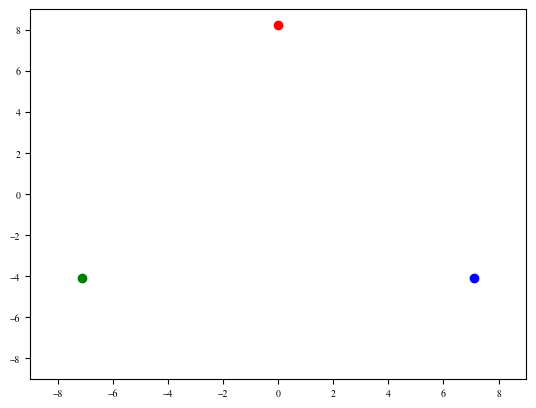

In [8]:
p0 = [0, 8.2, 0]
p1 = [-7.1014, -4.1, 0]
p2 = [7.1014, -4.1, 0]

plt.scatter(p0[0], p0[1], c="r")
plt.scatter(p1[0], p1[1], c="g")
plt.scatter(p2[0], p2[1], c="b")

plt.xlim(-9, 9)
plt.ylim(-9, 9)

np.linalg.norm(p0), np.linalg.norm(p1), np.linalg.norm(p2)

In [ ]:
ap0r = np.arctan2(p0[1], p0[0])
ap0d = np.degrees(ap0r)

ap1r = np.arctan2(p1[1], p1[0])
ap1d = np.degrees(ap1r)

ap1r = np.arctan2(p1[1], p1[0])
ap1d = np.degrees(ap1r)


In [115]:
sim_lst = ["m12b", "m12c", "m12f", "m12i", "m12m"]
sim_dir = "/Users/z5114326/Documents/simulations/"

mw_gcs_fil = "../data/mw_gcs/mw_gcs.csv"
mw_gcs = pd.read_csv(mw_gcs_fil)

mw_gcs_cols_fil = "../data/mw_gcs/mw_gcs_colors_ref.csv"
mw_gcs_cols = pd.read_csv(mw_gcs_cols_fil)

mw_gc_class = "../data/mw_gcs/class_chen.txt"
mw_class = pd.read_csv(mw_gc_class, sep=r"\s+")

mw_class.loc[mw_class["Cluster"] == "ESO-SC06", "Cluster"] = "ESO_280-SC06"
mw_class.loc[mw_class["Cluster"] == "1636-283", "Cluster"] = "ESO_452-SC11"

mw_class = mw_class.rename(columns={"Cluster": "cluster_name"})

sim_fit_path = "../data/sim_data/boundary_fits.json"
with open(sim_fit_path, "r", encoding="utf-8") as f:
    sim_fit_dict = json.load(f)

sim_fit_upd_path = "../data/sim_data/boundary_fits_updated.json"
with open(sim_fit_upd_path, "r", encoding="utf-8") as f:
    sim_fit_upd_dict = json.load(f)

scmap = plt.get_cmap("tab10")
colors = [scmap(i) for i in np.linspace(0, 1, len(sim_lst))]
sim_colors = {sim: colors[i] for i, sim in enumerate(sim_lst)}

fn0_json = "../data/mw_gcs/fno_mw_gcs.json"
with open(fn0_json, "r") as f:
    fn0_dict = json.load(f)

In [116]:
def lower_bound(x, m, b):
    return m * x + b


def kde_threshold(Z, fraction):
    """Return KDE level that encloses fraction of total probability."""
    sorted_Z = np.sort(Z.ravel())[::-1]  # descending
    cumsum = np.cumsum(sorted_Z)
    cumsum /= cumsum[-1]  # normalize
    # Find the smallest Z value where cumulative sum >= fraction
    level = sorted_Z[np.searchsorted(cumsum, fraction)]
    return level


def get_lower_bound(
    x,
    y,
    xlims=(3.0, 8.0),
    ylims=(-1.0, 3.0),
    ngrid=500,
    cont_lvl=0.98,
):

    xlog = np.log10(x)
    ylog = np.log10(y)
    xylog = np.vstack([xlog, ylog])

    xmin, xmax = xlims
    ymin, ymax = ylims

    X, Y = np.meshgrid(
        np.linspace(xmin, xmax, ngrid),
        np.linspace(ymin, ymax, ngrid),
    )

    kde = gaussian_kde(xylog)
    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)

    lvl = kde_threshold(Z, cont_lvl)

    cont = plt.contour(X, Y, Z, levels=[lvl])
    plt.close()

    contp = cont.get_paths()[0]
    vert = contp.vertices

    xcon = vert[:, 0]
    ycon = vert[:, 1]

    xbins = np.linspace(xcon.min(), xcon.max(), 100)
    xbins_cen = 0.5 * (xbins[:-1] + xbins[1:])

    x_lower = []
    y_lower = []

    for i in range(len(xbins) - 1):
        mask = (xcon >= xbins[i]) & (xcon < xbins[i + 1])

        if np.any(mask):
            x_lower.append(xbins_cen[i])
            y_lower.append(np.min(ycon[mask]))

    x_lower = np.asarray(x_lower)
    y_lower = np.asarray(y_lower)

    p0 = [-1.0, 1.0]
    params, cov = curve_fit(lower_bound, x_lower, y_lower, p0=p0)

    best_fit_dict = {
        "m": params[0],
        "b": params[1],
        "cov": cov,
    }

    xfit = np.logspace(xmin, xmax)
    xfitlog = np.log10(xfit)

    yfitlog = lower_bound(xfitlog, *params)
    yfit = 10**yfitlog

    return xfit, yfit, best_fit_dict


def to_json_serializable(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, dict):
        return {k: to_json_serializable(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [to_json_serializable(v) for v in obj]
    elif isinstance(obj, (np.integer, np.floating)):
        return obj.item()
    else:
        return obj

In [117]:
cont_lvl = 0.95
ngrid = 500

xmin, xmax = 3.0, 8.0
ymin, ymax = -1.0, 3.0
X, Y = np.meshgrid(np.linspace(xmin, xmax, ngrid), np.linspace(ymin, ymax, ngrid))

df_orb = mw_gcs.merge(
    mw_class[["cluster_name", "Origin"]],
    on="cluster_name",
    how="inner",
)

rsem = (df_orb["r_apo"] + df_orb["r_per"]) / 2
mini = 10 ** df_orb["log_mini"]
insitu = df_orb["Origin"] == "in-situ"

xi = mini[insitu]
yi = rsem[insitu]
xifit, yifit, fiti_dict = get_lower_bound(xi, yi)

xe = mini[~insitu]
ye = rsem[~insitu]
xefit, yefit, fite_dict = get_lower_bound(xe, ye)

bound_mw = {"in": fiti_dict, "ex": fite_dict}
bound_mw = to_json_serializable(bound_mw)

bound_mw_path = "../data/sim_data/boundary_mw_fits.json"
with open(bound_mw_path, "w", encoding="utf-8") as f:
    json.dump(bound_mw, f, indent=4)

In [118]:
mi_avg = np.round(fiti_dict["m"], 2)
mi_std = np.round(np.sqrt(fiti_dict["cov"][0, 0]), 2)
bi_avg = np.round(fiti_dict["b"], 2)
bi_std = np.round(np.sqrt(fiti_dict["cov"][1, 1]), 2)

print("MW in situ", "m:", mi_avg, "+/-", mi_std, "b:", bi_avg, "+/-", bi_std)

me_avg = np.round(fite_dict["m"], 2)
me_std = np.round(np.sqrt(fite_dict["cov"][0, 0]), 2)
be_avg = np.round(fite_dict["b"], 2)
be_std = np.round(np.sqrt(fite_dict["cov"][1, 1]), 2)

print("MW ex situ", "m:", me_avg, "+/-", me_std, "b:", be_avg, "+/-", be_std)

MW in situ m: -0.58 +/- 0.01 b: 3.46 +/- 0.06
MW ex situ m: -0.39 +/- 0.01 b: 2.77 +/- 0.06


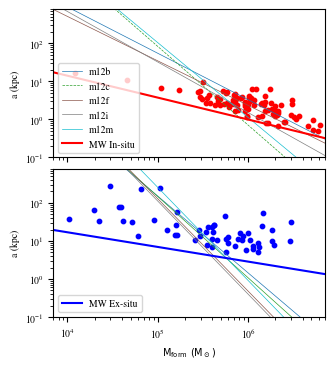

In [119]:
xmin, xmax = (3, 8)
xfitlog = np.linspace(xmin, xmax, 100)
xfit = 10**xfitlog

fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
plt.subplots_adjust(hspace=0.075)

# In-situ population ###########################################

for sim in sim_lst:
    if sim != "m12c":
        m = sim_fit_dict[sim]["in"]["m"]["50"]
        c = sim_fit_dict[sim]["in"]["c"]["50"]

        yfitlog = m * xfitlog + c
        yfit = 10**yfitlog

        axs[0].plot(xfit, yfit, c=sim_colors[sim], lw=0.5, label=sim)
    else:
        m = sim_fit_dict["m12c_5gyr_lim"]["in"]["m"]["50"]
        c = sim_fit_dict["m12c_5gyr_lim"]["in"]["c"]["50"]

        yfitlog = m * xfitlog + c
        yfit = 10**yfitlog

        axs[0].plot(xfit, yfit, c=sim_colors[sim], lw=0.5, ls="--", label="m12c")

axs[0].scatter(xi, yi, c="r", s=10)
axs[0].plot(xifit, yifit, c="r", label="MW In-situ")

axs[0].set_xscale("log")
axs[0].set_yscale("log")

axs[0].set_xlim(7 * 10**3, 7 * 10**6)
axs[0].set_ylim(10**-1, 8 * 10**2)

axs[0].set_xlabel("")
axs[0].set_xticklabels([])

axs[0].set_ylabel(r"a (kpc)")

axs[0].legend(loc="lower left")

# Ex-situ population ###########################################

for sim in sim_lst:
    m = sim_fit_dict[sim]["ex"]["m"]["50"]
    c = sim_fit_dict[sim]["ex"]["c"]["50"]

    yfitlog = m * xfitlog + c
    yfit = 10**yfitlog

    axs[1].plot(xfit, yfit, c=sim_colors[sim], lw=0.5)

axs[1].scatter(xe, ye, c="b", s=10)
axs[1].plot(xefit, yefit, c="b", label="MW Ex-situ")

axs[1].set_xscale("log")
axs[1].set_yscale("log")

axs[1].set_xlim(7 * 10**3, 7 * 10**6)
axs[1].set_ylim(10**-1, 8 * 10**2)

axs[1].set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")
axs[1].set_ylabel(r"a (kpc)")

axs[1].legend(loc="lower left")

mw_conts = "../data/figures/boundaries/mw_kde_boundaries.pdf"
fig.savefig(mw_conts)

# New Boundary Definition

In [120]:
# xmin, xmax = (3, 8)
# xfitlog = np.linspace(xmin, xmax, 100)
# xfit = 10**xfitlog

# fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
# plt.subplots_adjust(hspace=0.075)

# # In-situ population ###########################################

# for sim in sim_lst:
#     if sim != "m12c":
#         params = (sim_fit_upd_dict[sim]["in"]["avg"]["m"], sim_fit_upd_dict[sim]["in"]["avg"]["b"])

#         yfitlog = lower_bound(xfitlog, *params)
#         yfit = 10**yfitlog

#         axs[0].plot(xfit, yfit, c=sim_colors[sim], lw=1, label=sim)

#     else:
#         params = (
#             sim_fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["m"],
#             sim_fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["b"],
#         )

#         yfitlog = lower_bound(xfitlog, *params)
#         yfit = 10**yfitlog
#         axs[0].plot(xfit, yfit, c=sim_colors[sim], ls="--", lw=1, label="m12c")


# axs[0].scatter(xi, yi, c="r", s=10)
# axs[0].plot(xifit, yifit, c="r", label="Milky Way")

# axs[0].set_xscale("log")
# axs[0].set_yscale("log")

# axs[0].set_xlim(7 * 10**3, 7 * 10**6)
# axs[0].set_ylim(10**-1, 8 * 10**2)

# axs[0].set_xlabel("")
# axs[0].set_xticklabels([])

# axs[0].set_ylabel(r"a (kpc)")

# axs[0].legend(loc="lower left")

# # Ex-situ population ###########################################

# for sim in sim_lst:
#     params = (sim_fit_upd_dict[sim]["ex"]["avg"]["m"], sim_fit_upd_dict[sim]["ex"]["avg"]["b"])

#     yfitlog = lower_bound(xfitlog, *params)
#     yfit = 10**yfitlog

#     axs[1].plot(xfit, yfit, c=sim_colors[sim], lw=1)

# axs[1].scatter(xe, ye, c="b", s=10)
# axs[1].plot(xefit, yefit, c="b", label="Milky Way")

# axs[1].set_xscale("log")
# axs[1].set_yscale("log")

# axs[1].set_xlim(7 * 10**3, 7 * 10**6)
# axs[1].set_ylim(10**-1, 8 * 10**2)

# axs[1].set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")
# axs[1].set_ylabel(r"a (kpc)")

# axs[1].legend(loc="lower left")

# mw_conts = "../data/figures/boundaries/mw_kde_boundaries_updated.pdf"
# fig.savefig(mw_conts)

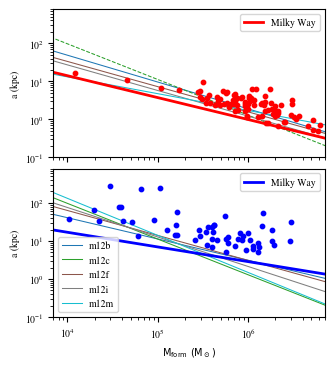

In [121]:
from matplotlib.lines import Line2D

xmin, xmax = (3, 8)
xfitlog = np.linspace(xmin, xmax, 100)
xfit = 10**xfitlog

fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
plt.subplots_adjust(hspace=0.075)

# In-situ population ###########################################

for sim in sim_lst:
    if sim != "m12c":
        params = (
            sim_fit_upd_dict[sim]["in"]["avg"]["m"],
            sim_fit_upd_dict[sim]["in"]["avg"]["b"],
        )

        yfitlog = lower_bound(xfitlog, *params)
        yfit = 10**yfitlog

        axs[0].plot(xfit, yfit, c=sim_colors[sim], lw=0.75, zorder=0)

    else:
        params = (
            sim_fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["m"],
            sim_fit_upd_dict["m12c_5gyr_lim"]["in"]["avg"]["b"],
        )

        yfitlog = lower_bound(xfitlog, *params)
        yfit = 10**yfitlog

        axs[0].plot(xfit, yfit, c=sim_colors[sim], ls="--", lw=0.75, zorder=0)

axs[0].scatter(xi, yi, c="r", s=10)
axs[0].plot(xifit, yifit, c="r", lw=2)

axs[0].set_xscale("log")
axs[0].set_yscale("log")

axs[0].set_xlim(7 * 10**3, 7 * 10**6)
axs[0].set_ylim(10**-1, 8 * 10**2)

axs[0].set_xlabel("")
axs[0].set_xticklabels([])

axs[0].set_ylabel(r"a (kpc)")

# MW legend only (upper right)
axs[0].legend(
    handles=[
        Line2D([], [], color="r", lw=2, label="Milky Way"),
    ],
    loc="upper right",
)

# Ex-situ population ###########################################

for sim in sim_lst:
    params = (
        sim_fit_upd_dict[sim]["ex"]["avg"]["m"],
        sim_fit_upd_dict[sim]["ex"]["avg"]["b"],
    )

    yfitlog = lower_bound(xfitlog, *params)
    yfit = 10**yfitlog

    axs[1].plot(xfit, yfit, c=sim_colors[sim], lw=0.75, label=sim, zorder=0)

axs[1].scatter(xe, ye, c="b", s=10)
axs[1].plot(xefit, yefit, c="b", lw=2)

axs[1].set_xscale("log")
axs[1].set_yscale("log")

axs[1].set_xlim(7 * 10**3, 7 * 10**6)
axs[1].set_ylim(10**-1, 8 * 10**2)

axs[1].set_xlabel(r"$\mathrm{M}_\mathrm{form}\ (\mathrm{M}_\odot)$")
axs[1].set_ylabel(r"a (kpc)")

# Simulation legend (bottom left)
sim_legend = axs[1].legend(loc="lower left")

# MW legend (upper right)
mw_legend = axs[1].legend(
    handles=[
        Line2D([], [], color="b", lw=2, label="Milky Way"),
    ],
    loc="upper right",
)

axs[1].add_artist(sim_legend)

mw_conts = "../data/figures/boundaries/mw_kde_boundaries_updated.pdf"
fig.savefig(mw_conts)

# Implying MW mass loss:

In [122]:
def safe_interpolate(x, y, mass_grid):
    interp_func = interp1d(x, y, kind="linear", bounds_error=False, fill_value=(0, 1))
    return interp_func(mass_grid)


def get_cdf(arr):
    return np.cumsum(arr) / np.sum(arr)

In [123]:
mw_mform = 10 ** mw_gcs["log_mini"]
mw_mz0 = mw_gcs["mass"]

MW_halo_med = 1.4 * 1e9
MW_halo_hi = (1.4 + 0.4) * 1e9
MW_halo_lo = (1.4 - 0.4) * 1e9

A = fn0_dict["A"]
B = fn0_dict["B"]
C = fn0_dict["C"]

In [124]:
min_masss = [10**4, 10**5]
max_masss = 10 ** np.arange(4, 7.1, 0.1)

# 1P - Field
# 2P - Enriched

mass_dict = {
    sim: {
        mlim: {"gc": {"1P": [], "2P": [], "tot": []}, "field": {"1P": [], "2P": [], "tot": []}}
        for mlim in min_masss
    }
    for sim in sim_lst
}

# Assumin equal loss of populations

for sim in sim_lst:
    ghost_file = f"{sim_dir}{sim}/{sim}_ghosts.hdf5"
    ghost_data = h5py.File(ghost_file, "r")

    for mlim in min_masss:
        for it_id in ghost_data.keys():
            src_dat = ghost_data[it_id]["source"]

            log_mfors = src_dat["logm_tfor"][()]
            mfors = 10**log_mfors
            fmsk = mfors >= mlim

            log_fnos = A + B * log_mfors + C * log_mfors**2
            fnos = 10**log_fnos

            mfor_evs = 0.55 * mfors
            mz0 = np.array([0 if m0 == -1 else 10**m0 for m0 in src_dat["logm_tz0"][()]])
            mdifs = mfor_evs - mz0

            gc_tots = []
            gc_1Ps = []
            gc_2Ps = []

            field_tots = []
            field_1Ps = []
            field_2Ps = []

            # --- masks ---
            for max_mass in max_masss:
                mmsk = mfors <= max_mass

                gc_tots.append(np.sum(mz0[fmsk & mmsk]))
                gc_1Ps.append(np.sum((1 - fnos[fmsk & mmsk]) * mz0[fmsk & mmsk]))
                gc_2Ps.append(np.sum((fnos[fmsk & mmsk]) * mz0[fmsk & mmsk]))

                field_tots.append(np.sum(mdifs[fmsk & mmsk]))
                field_1Ps.append(np.sum((1 - fnos[fmsk & mmsk]) * mdifs[fmsk & mmsk]))
                field_2Ps.append(np.sum((fnos[fmsk & mmsk]) * mdifs[fmsk & mmsk]))

            mass_dict[sim][mlim]["gc"]["tot"].append(np.array(gc_tots))
            mass_dict[sim][mlim]["gc"]["1P"].append(np.array(gc_1Ps))
            mass_dict[sim][mlim]["gc"]["2P"].append(np.array(gc_2Ps))

            mass_dict[sim][mlim]["field"]["tot"].append(np.array(field_tots))
            mass_dict[sim][mlim]["field"]["1P"].append(np.array(field_1Ps))
            mass_dict[sim][mlim]["field"]["2P"].append(np.array(field_2Ps))


MW MASS at log(m) = 4.0
MW surviving GC mass = 3.72e+07 Msun

MW GC-origin field mass:
Preferred (percentiles): 2.88e+08 Msun
68% interval: [2.19e+08, 3.93e+08] Msun



MW MASS at log(m) = 5.0
MW surviving GC mass = 3.72e+07 Msun

MW GC-origin field mass:
Preferred (percentiles): 1.31e+08 Msun
68% interval: [1.01e+08, 1.84e+08] Msun




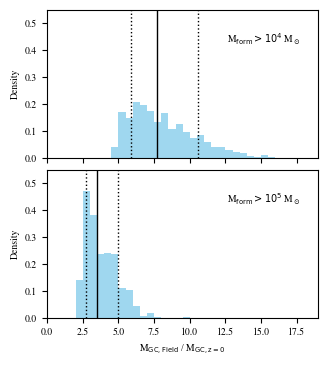

In [125]:
Msurv_MW = np.sum(mw_mz0)
# Msurv_MW = 2.5 * 1e7

fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
plt.subplots_adjust(hspace=0.075)
Rbins = np.arange(0, 21, 0.5)

mw_gc_field = {mlim: {"lo": None, "med": None, "hi": None} for mlim in min_masss}

for i, mlim in enumerate(min_masss):
    R_surv = []

    for sim in sim_lst:
        for idx in range(0, len(mass_dict[sim][mlim]["field"]["tot"])):
            R_surv.append(
                mass_dict[sim][mlim]["field"]["tot"][idx][-1] / mass_dict[sim][mlim]["gc"]["tot"][idx][-1]
            )
    R_surv = np.asarray(R_surv)

    # ==========================================================
    # SIMULATION CALIBRATION
    # ==========================================================

    Rmed = np.median(R_surv)
    R16 = np.percentile(R_surv, 16)
    R84 = np.percentile(R_surv, 84)

    # ==========================================================
    # MILKY WAY
    # ==========================================================

    Mfield_med = Rmed * Msurv_MW
    Mfield_lo = R16 * Msurv_MW
    Mfield_hi = R84 * Msurv_MW

    # ==========================================================
    # OUTPUT
    # ==========================================================

    print()
    print("MW MASS at log(m) =", np.log10(mlim))
    print("=================================================")

    print(f"MW surviving GC mass = {Msurv_MW:.2e} Msun")

    print()
    print("MW GC-origin field mass:")

    print(f"Preferred (percentiles): {Mfield_med:.2e} Msun")

    print(f"68% interval: [{Mfield_lo:.2e}, {Mfield_hi:.2e}] Msun")
    print()
    print()

    mw_gc_field[mlim]["lo"] = Mfield_lo
    mw_gc_field[mlim]["med"] = Mfield_med
    mw_gc_field[mlim]["hi"] = Mfield_hi

    # ==========================================================
    # PLOT
    # ==========================================================

    axs[i].hist(R_surv, bins=Rbins, density=True, alpha=0.8, color="skyblue")

    axs[i].axvline(Rmed, c="k", lw=1)
    axs[i].axvline(R16, c="k", ls=":", lw=1)
    axs[i].axvline(R84, c="k", ls=":", lw=1)

    axs[i].set_ylabel("Density")

    axs[i].set_xlim(0, 19)
    axs[i].set_ylim(0, 0.55)

    txt = rf"M$_{{\rm form}} > 10^{{{np.log10(mlim):.0f}}}$ M$_\odot$"
    axs[i].text(0.80, 0.80, txt, transform=axs[i].transAxes, ha="center", va="center")

axs[0].set_xticklabels([])
axs[1].set_xlabel(r"M$_{\rm GC,Field}$ / M$_{\rm GC,z=0}$")

plt.show()

mass_field = "../data/figures/gc_plots/mass_field_ratios.pdf"
fig.savefig(mass_field, bbox_inches="tight")

In [126]:
# Mass Fractions


halo_frac_lo = mw_gc_field[min_masss[0]]["lo"] / MW_halo_hi
halo_frac_med = mw_gc_field[min_masss[0]]["med"] / MW_halo_med
halo_frac_hi = mw_gc_field[min_masss[0]]["hi"] / MW_halo_lo

halo_frac_lo, halo_frac_med, halo_frac_hi

(0.12147481570650531, 0.2055027678225653, 0.3931326104720163)

In [127]:
halo_frac_lo = mw_gc_field[min_masss[1]]["lo"] / MW_halo_hi
halo_frac_med = mw_gc_field[min_masss[1]]["med"] / MW_halo_med
halo_frac_hi = mw_gc_field[min_masss[1]]["hi"] / MW_halo_lo

halo_frac_lo, halo_frac_med, halo_frac_hi

(0.05617740318426232, 0.09324794658531478, 0.18390745317489923)


MW MASS at log(m) = 4.0
MW 2P halo mass = 1.53e+07 Msun
[1.10e+07, 2.34e+07]

MW MASS at log(m) = 5.0
MW 2P halo mass = 2.78e+07 Msun
[2.04e+07, 4.17e+07]


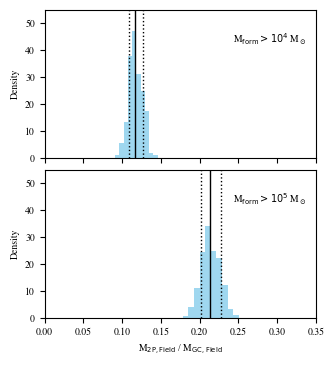

In [128]:
fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
plt.subplots_adjust(hspace=0.075)

en_fracs = {mlim: [] for mlim in min_masss}
en_bins = np.arange(0.08, 0.26, 0.01)

for i, mlim in enumerate(min_masss):
    for sim in sim_lst:
        for idx in range(0, len(mass_dict[sim][mlim]["field"]["tot"])):
            en_fracs[mlim].append(
                mass_dict[sim][mlim]["field"]["2P"][idx][-1] / mass_dict[sim][mlim]["field"]["tot"][idx][-1]
            )

    en_med = np.median(en_fracs[mlim])
    en_lo = np.percentile(en_fracs[mlim], 16)
    en_hi = np.percentile(en_fracs[mlim], 84)

    # axs[i].hist(en_fracs[mlim], bins=en_bins, density=True, alpha=0.8, color="skyblue")
    axs[i].hist(en_fracs[mlim], density=True, alpha=0.8, color="skyblue")

    axs[i].axvline(en_med, c="k", lw=1)
    axs[i].axvline(en_lo, c="k", ls=":", lw=1)
    axs[i].axvline(en_hi, c="k", ls=":", lw=1)

    axs[i].set_ylabel("Density")

    axs[i].set_xlim(0.0, 0.35)
    axs[i].set_ylim(0, 55)

    txt = rf"M$_{{\rm form}} > 10^{{{np.log10(mlim):.0f}}}$ M$_\odot$"
    axs[i].text(0.83, 0.80, txt, transform=axs[i].transAxes, ha="center", va="center")

    axs[0].set_xticklabels([])
    axs[1].set_xlabel(r"M$_{\rm 2P,Field}$ / M$_{\rm GC,Field}$")

    print()
    print("MW MASS at log(m) =", np.log10(mlim))

    print("=================================================")

    print(f"MW 2P halo mass = {(Mfield_med * en_med):.2e} Msun")
    print(f"[{(Mfield_lo * en_lo):.2e}, {(Mfield_hi * en_hi):.2e}]")

mw_enrich_field = "../data/figures/gc_plots/2P_field_ratios.pdf"
fig.savefig(mw_enrich_field, bbox_inches="tight")

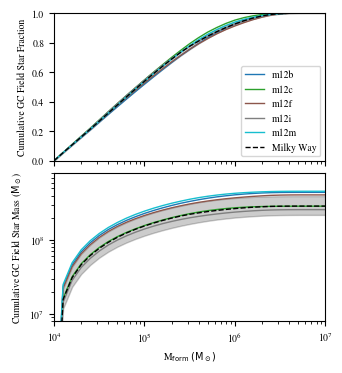

In [140]:
mlim = min_masss[0]

Ffield_sims_tot = np.array(
    [np.mean([m / m[-1] for m in mass_dict[sim][mlim]["field"]["tot"]], axis=0) for sim in sim_lst]
)

Ffield_sim_tot = np.median(Ffield_sims_tot, axis=0)
Ffield_sim_tot_16 = np.percentile(Ffield_sims_tot, 16, axis=0)
Ffield_sim_tot_84 = np.percentile(Ffield_sims_tot, 84, axis=0)

# Ffield_sims_1P = np.array(
#     [np.mean([m / m[-1] for m in mass_dict[sim][mlim]["field"]["1P"]], axis=0) for sim in sim_lst]
# )

# Ffield_sim_1P = np.median(Ffield_sims_1P, axis=0)
# Ffield_sim_1P_16 = np.percentile(Ffield_sims_1P, 16, axis=0)
# Ffield_sim_1P_84 = np.percentile(Ffield_sims_1P, 84, axis=0)


# Ffield_sims_2P = np.array(
#     [np.mean([m / m[-1] for m in mass_dict[sim][mlim]["field"]["2P"]], axis=0) for sim in sim_lst]
# )

# Ffield_sim_2P = np.median(Ffield_sims_2P, axis=0)
# Ffield_sim_2P_16 = np.percentile(Ffield_sims_2P, 16, axis=0)
# Ffield_sim_2P_84 = np.percentile(Ffield_sims_2P, 84, axis=0)


# ----------------------------------------------------------
# MW cumulative field mass
# ----------------------------------------------------------

Mfield_cum_tot_MW = mw_gc_field[mlim]["med"] * Ffield_sim_tot
Mfield_cum_tot_lo = mw_gc_field[mlim]["lo"] * Ffield_sim_tot_16
Mfield_cum_tot_hi = mw_gc_field[mlim]["hi"] * Ffield_sim_tot_84

# Mfield_cum_1P_MW = mw_gc_field[mlim]["med"] * Ffield_sim_1P
# Mfield_cum_1P_lo = mw_gc_field[mlim]["lo"] * Ffield_sim_1P_16
# Mfield_cum_1P_hi = mw_gc_field[mlim]["hi"] * Ffield_sim_1P_84

# Mfield_cum_2P_MW = mw_gc_field[mlim]["med"] * Ffield_sim_2P
# Mfield_cum_2P_lo = mw_gc_field[mlim]["lo"] * Ffield_sim_2P_16
# Mfield_cum_2P_hi = mw_gc_field[mlim]["hi"] * Ffield_sim_2P_84

fig, axs = plt.subplots(2, 1, figsize=(3.5, 4.0))
plt.subplots_adjust(hspace=0.085)


for sim in sim_lst:
    Ffield = np.mean([m / m[-1] for m in mass_dict[sim][mlim]["field"]["tot"]], axis=0)

    axs[0].plot(max_masss, Ffield, alpha=1, lw=1, color=sim_colors[sim], label=sim)

axs[0].plot(max_masss, Ffield_sim_tot, c="k", lw=1, label="Milky Way", ls="--")
axs[0].fill_between(max_masss, Ffield_sim_tot_16, Ffield_sim_tot_84, color="k", alpha=0.2)
axs[0].set_xscale("log")
axs[0].set_xticklabels([])

axs[0].set_xlim(1e4, 1e7)
axs[0].set_ylim(0, 1)

axs[0].set_ylabel(r"Cumulative GC Field Star Fraction")

axs[0].legend(loc="lower right")

for sim in sim_lst:
    Ffield = np.mean([m / m[-1] for m in mass_dict[sim][mlim]["field"]["tot"]], axis=0)
    # total field mass for this simulation
    Mfield_sim_tot = np.mean([m[-1] for m in mass_dict[sim][mlim]["field"]["tot"]], axis=0)

    axs[1].plot(max_masss, Mfield_sim_tot * Ffield, alpha=1, lw=1, color=sim_colors[sim], label=sim)

axs[1].plot(max_masss, Mfield_cum_tot_MW, c="k", lw=1, label="Milky Way", ls="--")
axs[1].fill_between(max_masss, Mfield_cum_tot_lo, Mfield_cum_tot_hi, color="k", alpha=0.2)

axs[1].set_xscale("log")
axs[1].set_yscale("log")

axs[1].set_xlim(1e4, 1e7)
axs[1].set_ylim(0.8e7, 0.8e9)

axs[1].set_ylabel(r"Cumulative GC Field Star Mass ($\text{M}_\odot$)")

# ax[1].set_xlim(1e4, 1e7)

axs[1].set_xlabel(r"M$_{\rm form}$ $({\rm M}_\odot)$")
# ax[1].set_ylabel(r"Cumulative GC-Origin Field Mass")

cum_field = "../data/figures/gc_plots/cumulative_mass_field.pdf"
fig.savefig(cum_field, bbox_inches="tight")